In [92]:
import os
os.environ["XLA_FLAGS"] = "--xla_force_host_platform_device_count=10"

# os.environ["XLA_PYTHON_CLIENT_ALLOCATOR"] = "platform" 
# This makes JAX allocate exactly what is needed on demand, and deallocate memory that is no longer needed (note that this is the only configuration that will deallocate GPU memory, instead of reusing it). This is very slow, so is not recommended for general use, but may be useful for running with the minimal possible GPU memory footprint or debugging OOM failures.

os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = ".95"
os.environ["CUDA_VISIBLE_DEVICES"] = "1"

import jax
import jax.numpy as jnp
from jax import random
import jax.numpy as jnp
from jax import random
import numpy as np
import matplotlib.pyplot as plt
from flax import linen as nn
import optax
import jax
import jax.numpy as jnp
from jax import random, jit
import optax
from tqdm import tqdm
import matplotlib.pyplot as plt
# Assuming equivalent JAX implementations
from src.subspace_curve import pytree_to_matrix
import wandb
from src.models import ResNet, ResNetBlock, init_t_lambda_to_phi, init_model_tube, init_model_phi
from jax_tqdm import scan_tqdm
from torch.utils.data import random_split
import torch
import torchvision
from torch.utils.data import TensorDataset
import pandas as pd
from src.models import MLPModel


%load_ext autoreload
%autoreload 2

# %env XLA_FLAGS="--xla_force_host_platform_device_count=10"
# os.environ["XLA_FLAGS"] = "--xla_force_host_platform_device_count=10"
# os.environ["XLA_FLAGS"] = ('--xla_force_host_platform_device_count=10 '
#                            '--xla_dump_to=xla_dump/')
%env XLA_FLAGS

#jax.devices("gpu")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


'--xla_force_host_platform_device_count=10'

In [93]:
def gen_data(rng_seed, net_kwargs, **kwargs):
    rng_key = random.PRNGKey(rng_seed + 1133)
    x = jnp.linspace(-2, 2, 100)
    x = x[(jnp.abs(x) > 0.6)].reshape(-1, 1)

    # define ground trouth model
    rng_key, rng_init = random.split(rng_key)
    model_gen = MLPModel(**net_kwargs)
    params = model_gen.init(rng_init, x)

    # generate train data
    y_gt = model_gen.apply(params, x).squeeze()
    rng_key, rng = random.split(rng_key)
    y = y_gt + jax.random.normal(rng, y_gt.shape) * 0.05

    # generate valid data
    x_val = jnp.linspace(-2, 2, 25)
    x_val = x_val[(jnp.abs(x_val) > 0.6)].reshape(-1, 1)
    y_gt_val = model_gen.apply(params, x_val).squeeze()
    rng_key, rng = random.split(rng_key)
    y_val = y_gt_val + jax.random.normal(rng, y_gt_val.shape) * 0.05

    xt = jnp.linspace(-2.5, 2.5, 1000).reshape(-1, 1)
    rng_key, rng = random.split(rng_key)
    y_gtt = model_gen.apply(params, xt).squeeze()
    yt = y_gtt + jax.random.normal(rng, y_gtt.shape) * 0.05

    return x, y, x_val, y_val, xt, yt, y_gtt

Data shapes: (70, 1) (70,) (18, 1) (1000, 1)


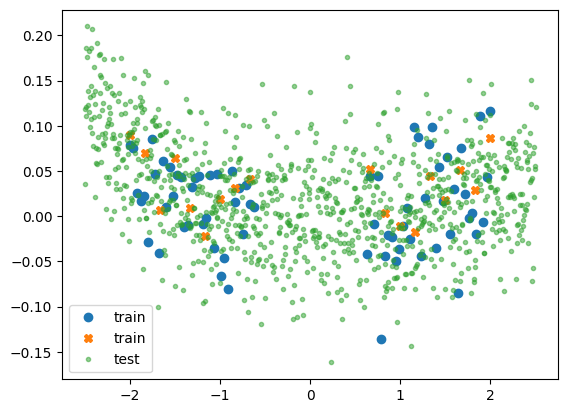

In [94]:
config = {'rng_seed': 0,
          'num_epochs': 500,
          'batch_size': 100,
          'optimizer_conf': {'name': "optax.sgd", 'kwargs': {'learning_rate': 0.05, 'momentum': 0.9, 'nesterov': True}},
          'net_kwargs': {'depth': 10, 'width': 10, 'activation': "relu"}}

x, y, x_val, y_val, xt, yt, y_gtt = gen_data(**config)
plt.plot(x, y, 'o', label='train')
plt.plot(x_val, y_val, 'X', label='train')
plt.plot(xt, yt, '.', label='test', alpha=0.5)
plt.legend()
print("Data shapes:", x.shape, y.shape, x_val.shape, xt.shape)


In [11]:
from src.subspace_curve import CategorySubspace
from src.models import ResNet, ResNetBlock, MLPModel

temp_x = jnp.ones((10, 32, 32, 3))
temp_y = jax.random.randint(random.PRNGKey(0), (10,), 0, 3)
model = ResNet(num_classes=3, num_blocks=(1,), block_class=ResNetBlock, act_fn=nn.elu)

s_model = CategorySubspace(
    model=model,
    k=1,
    weight_decay=0.01,
    perm_spec=None,  # PermutationSpec(2, 3),
    natural_parameterization=False,
    mutuable_param_name='batch_stats' if isinstance(model, ResNet) else False
)
mask = s_model.init_mask(temp_x, all_curves=True)
# mask['Dense_2']['bias'] = False  # do curve bias
# mask['Dense_2']['kernel'] = False  # do curve kernel
params = s_model.init_params(random.PRNGKey(0), temp_x, mask)
for p in jax.tree.flatten(params['params'])[0]:
    print(p.shape)
out, batch_stats = s_model(params['params'], params['batch_stats'], t=0.5, x=temp_x, train=True)
print("Out shape: ", out.shape)

opti = optax.sgd(learning_rate=0.05, momentum=0.9, nesterov=True)
opt_state = opti.init(params['params'])
loss, params, opt_state, grads = s_model.train_step(random.PRNGKey(0), params, temp_x, temp_y, opt_state=opt_state, optimizer=opti)
# Check that the output shapes are the same
loss

(2, 16)
(2, 16)
(2, 3, 3, 3, 16)
(2, 3)
(2, 16, 3)
(2, 16)
(2, 16)
(2, 16)
(2, 16)
(2, 3, 3, 16, 16)
(2, 3, 3, 16, 16)
Out shape:  (10, 3)


Array(3.569724, dtype=float32)

In [95]:
from src.subspace_curve import RegressionSubspace, DistRegressionSubspace, RepulsiveDistRegressionSubspace
temp_x = jnp.ones((10, 1))
temp_y = jax.random.normal(random.PRNGKey(0), (10,1))
model = MLPModel(depth=3, width=5, activation='elu')


s_model = DistRegressionSubspace(
    model=model,
    k=1,
    weight_decay=0.01,
    perm_spec=None,  # PermutationSpec(2, 3),
    natural_parameterization=False,
    mutuable_param_name='batch_stats' if isinstance(model, ResNet) else False
)
mask = s_model.init_mask(temp_x, all_curves=True)
mask['Dense_2']['bias'] = False  # do curve bias
mask['Dense_2']['kernel'] = False  # do curve kernel
params = s_model.init_params(random.PRNGKey(0), temp_x, mask)
for p in jax.tree.flatten(params['params'])[0]:
    print(p.shape)
out, batch_stats = s_model(params['params'], {}, t=0.5, x=temp_x, train=True)
print("Out shape: ", out.shape)

opti = optax.sgd(learning_rate=0.05, momentum=0.9, nesterov=True)
opt_state = opti.init(params['params'])
loss, params, opt_state, grads = s_model.train_step(random.PRNGKey(0), params, temp_x, temp_y, opt_state=opt_state, optimizer=opti)
# Check that the output shapes are the same
loss

{'Dense_0': {'bias': True, 'kernel': True}, 'Dense_1': {'bias': True, 'kernel': True}, 'Dense_2': {'bias': False, 'kernel': False}, 'Dense_3': {'bias': True, 'kernel': True}}
(2, 5)
(2, 3, 5)
(2, 5)
(2, 5, 5)
(5,)
(5, 5)
(2, 1)
(2, 5, 1)
()
Out shape:  (10, 1)


Array(1.2986622, dtype=float32)

{'mse_val_curve': Array(0.13259229, dtype=float32), 'nll_val_curve': Array(0.9252702, dtype=float32)}
{'mse_test_curve': Array(0.24132161, dtype=float32), 'nll_test_curve': Array(0.9877937, dtype=float32)}
{'mse_val_curve_last': Array(0.13259229, dtype=float32), 'nll_val_curve_last': Array(0.9252702, dtype=float32)}
{'mse_test_curve_last': Array(0.24132161, dtype=float32), 'nll_test_curve_last': Array(0.9877937, dtype=float32)}


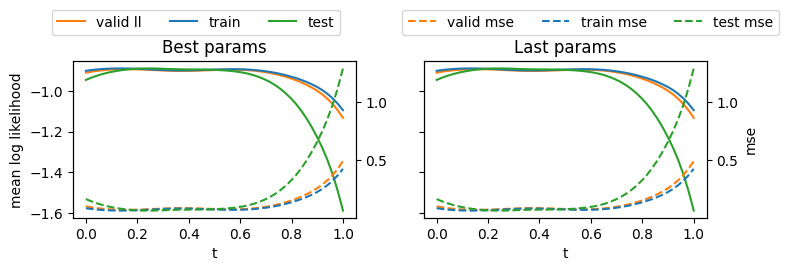

In [99]:
from toyReg_PtoC import setup_metrics

fig, ax = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
t_space = jnp.linspace(0, 1, 50)
valid_metrics_fn_final = setup_metrics(s_model, 18, x_val, y_val, n_samples=50, use_linspace=True, average=False)
train_metrics_fn_final = setup_metrics(s_model, 70, x, y, n_samples=50, use_linspace=True, average=False)
test_metrics_fn_final = setup_metrics(s_model, 250, xt, yt, n_samples=50, use_linspace=True, average=False)

# valid
rng_key = random.PRNGKey(0)
nll, mse = valid_metrics_fn_final(rng_key, params)
print({'mse_val_curve': mse.mean(), 'nll_val_curve': nll.mean()})
ax[0].plot(t_space, -nll, label="valid ll", c=plt.get_cmap('tab10')(1))
ax2 = ax[0].twinx()
ax2.plot(t_space, mse, label="valid mse",
            c=plt.get_cmap('tab10')(1), linestyle="--")
# train
nll, mse = train_metrics_fn_final(rng_key, params)
ax[0].plot(t_space, -nll, label="train", c=plt.get_cmap('tab10')(0))
ax2.plot(t_space, mse, label="train mse",
            c=plt.get_cmap('tab10')(0), linestyle="--")
# test
nll, mse = test_metrics_fn_final(rng_key, params)
print({'mse_test_curve': mse.mean(), 'nll_test_curve': nll.mean()})
ax[0].plot(t_space, -nll, label="test", c=plt.get_cmap('tab10')(2))
ax2.plot(t_space, mse, label="test mse",
            c=plt.get_cmap('tab10')(2), linestyle="--")
ax[0].set_xlabel("t")
ax[0].set_ylabel("mean log likelihood")
ax[0].set_title("Best params")

# valid
last_params = params
nll, mse = valid_metrics_fn_final(rng_key, last_params)
print({'mse_val_curve_last': mse.mean(), 'nll_val_curve_last': nll.mean()})
ax[1].plot(t_space, -nll, label="valid ll", c=plt.get_cmap('tab10')(1))
ax2 = ax[1].twinx()
ax2.plot(t_space, mse, label="valid mse",
            c=plt.get_cmap('tab10')(1), linestyle="--")
# train
nll, mse = train_metrics_fn_final(rng_key, last_params)
ax[1].plot(t_space, -nll, label="train", c=plt.get_cmap('tab10')(0))
ax2.plot(t_space, mse, label="train mse",
            c=plt.get_cmap('tab10')(0), linestyle="--")
# test
nll, mse = test_metrics_fn_final(rng_key, last_params)
print({'mse_test_curve_last': mse.mean(), 'nll_test_curve_last': nll.mean()})
ax[1].plot(t_space, -nll, label="test", c=plt.get_cmap('tab10')(2))
ax2.plot(t_space, mse, label="test mse",
            c=plt.get_cmap('tab10')(2), linestyle="--")
ax[1].set_xlabel("t")
ax2.set_ylabel("mse")
ax[0].legend(loc='center left', bbox_to_anchor=(-0.1, 1.25), ncol=3)
ax[1].set_title("Last params")
ax2.legend(loc='center left', bbox_to_anchor=(-0.1, 1.25), ncol=3)
plt.tight_layout()

In [79]:
from src.subspace_curve import RegressionSubspace, DistRegressionSubspace, RepulsiveDistRegressionSubspace, RepulsiveRegressionSubspace
temp_x = jnp.ones((10, 1))
temp_y = jax.random.normal(random.PRNGKey(0), (10,1))
model = MLPModel(depth=3, width=5, activation='elu')


s_model = RepulsiveDistRegressionSubspace(
    model=model,
    k=0,
    weight_decay=0.01,
    perm_spec=None,  # PermutationSpec(2, 3),
    natural_parameterization=False,
    mutuable_param_name='batch_stats' if isinstance(model, ResNet) else False,
    regularizer = "cosine"
)
mask = s_model.init_mask(temp_x, all_curves=False)
mask['Dense_2']['bias'] = True  # do curve bias
mask['Dense_2']['kernel'] = True  # do curve kernel
params = s_model.init_params(random.PRNGKey(0), temp_x, mask)
for p in jax.tree.flatten(params['params'])[0]:
    print(p.shape)
out, batch_stats = s_model(params['params'], {}, t=0.5, x=temp_x, train=True)
print("Out shape: ", out.shape)

opti = optax.sgd(learning_rate=0.05, momentum=0.9, nesterov=True)
opt_state = opti.init(params['params'])
loss, params, opt_state, grads = s_model.train_step(random.PRNGKey(0), params, temp_x, temp_y, opt_state=opt_state, optimizer=opti)
# Check that the output shapes are the same
loss

{'Dense_0': {'bias': False, 'kernel': False}, 'Dense_1': {'bias': False, 'kernel': False}, 'Dense_2': {'bias': True, 'kernel': True}, 'Dense_3': {'bias': False, 'kernel': False}}
(5,)
(3, 5)
(5,)
(5, 5)
(1, 5)
(1, 5, 5)
(1,)
(5, 1)
()
Out shape:  (10, 1)


Array(1.1795386, dtype=float32)

In [76]:
from copy import deepcopy

temp_x = jnp.ones((10, 1))
temp_y = jax.random.normal(random.PRNGKey(0), (10,1))
model = MLPModel(depth=3, width=5, activation='elu')
init_params = model.init(random.PRNGKey(0), temp_x)

s_model = RepulsiveRegressionSubspace(
    model=model,
    k=1,
    weight_decay=0.01,
    perm_spec=None,  # PermutationSpec(2, 3),
    natural_parameterization=False,
    mutuable_param_name='batch_stats' if isinstance(model, ResNet) else False,
    regularizer = "cosine"
)
mask = s_model.init_mask(temp_x, all_curves=False)
mask['Dense_2']['bias'] = True  # do curve bias
mask['Dense_2']['kernel'] = True  # do curve kernel

params = s_model.init_params_from_point(key=random.PRNGKey(0), point=init_params, mask=mask, jitter=1e-6)

for p in jax.tree.flatten(params['params'])[0]:
    print(p.shape)

params['params']['Dense_2']['bias']

(5,)
(3, 5)
(5,)
(5, 5)
(2, 5)
(2, 5, 5)
(1,)
(5, 1)


Array([[-2.6328860e-07,  1.2015249e-06,  3.9223087e-09,  5.9714375e-07,
        -5.8692882e-07],
       [ 5.5833033e-07,  2.2071972e-06, -6.3644217e-07, -9.0532609e-07,
         1.3979794e-06]], dtype=float32)

In [74]:
init_params['params']['Dense_2']['bias']

Array([0., 0., 0., 0., 0.], dtype=float32)

In [91]:
jnp.linspace(0, 1., 1)

Array([0.], dtype=float32)